# Annotator Certainty and "Not Visible" Encodings (R2)

`dataPrep.ipynb` builds three ways of handling attributes marked **"not visible"** (variants A, B, C) and has an optional
switch, `DROP_GUESSING_POSITIVES`, which is marked **"not evaluated"** there. The decision tree and random forest
notebooks compared A/B/C for trees only.

This notebook completes that evidence: it tests all the options, **including the guessing switch**, with three
other course models (logistic regression, k-NN and a decision tree), so the cleaning decision is backed for every
model family used in R3.

**Input:** `data/cub_features_A/B/C.csv` from [`dataPrep.ipynb`](dataPrep.ipynb), and the certainty labels from
`CUB_200_2011/attributes/image_attribute_labels_clean.txt`.
**Output:** one figure (`documentation/figures/certainty_experiment.png`) and the decision below. No data is changed.

**Protocol (same as the model notebooks):** official split, stratified 5-fold CV on the **training set only**, macro-F1
(every species counts equally). The test set is not used, so this cleaning choice cannot leak into test results.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split, same as the main model notebooks
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'documentation' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train']  # never used as features

# One consistent look for every figure
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 9, 'legend.frameon': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

def load_features(variant='A'):
    """Feature table written by dataPrep.ipynb (variant A = raw 0/1 attributes)."""
    path = DATA / f'cub_features_{variant}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path).copy()   # .copy() keeps the 300+ columns in one memory block
    df['species'] = df.class_name.str.split('.', n=1).str[1].str.replace('_', ' ')
    return df.copy()

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')

# Dataset folder, found the same way as in dataPrep.ipynb: inside data/raw/, or CUB_200_2011/ at the repo root
CUB = next((p.parent for p in (ROOT / 'data' / 'raw').rglob('image_class_labels.txt')), ROOT / 'CUB_200_2011')
assert CUB.exists(), 'Dataset not found - see README "Getting the data"'

## 2. The options being compared

| Option | Source | Present | Absent | Not visible | Guessed as present |
|---|---|---|---|---|---|
| **A** (baseline) | `dataPrep` variant A | 1 | 0 | 0 | 1 |
| **A, guesses dropped** | `dataPrep` with `DROP_GUESSING_POSITIVES = True` | 1 | 0 | 0 | **0** |
| **B** | `dataPrep` variant B | 1 | 0 | **−1** | 1 |
| **C** | `dataPrep` variant C | 1 | 0 | 0 (+ 28 per-body-part flags) | 1 |

The "guesses dropped" option is built here exactly as `dataPrep.ipynb` §6 would build it, so no data file has to change.

In [2]:
variants = {name: load_features(name) for name in ['A', 'B', 'C']}

# Certainty of every (image, attribute) label: 1 not visible, 2 guessing, 3 probably, 4 definitely
labels = pd.read_csv(CUB / 'attributes' / 'image_attribute_labels_clean.txt', sep=r'\s+', header=None,
                     names=['image_id', 'attr_id', 'is_present', 'certainty', 'time'])
attr_names = pd.read_csv(CUB / 'attributes' / 'attributes.txt', sep=' ', header=None,
                         names=['attr_id', 'attr_name']).set_index('attr_id').attr_name
certainty = labels.pivot(index='image_id', columns='attr_id', values='certainty').rename(columns=attr_names)

# Same rule as dataPrep's DROP_GUESSING_POSITIVES switch: a 'guessing' positive becomes 0
A = variants['A'].set_index('image_id')
ATTR = [c for c in A.columns if c not in META_COLS + ['species']]
guessing_pos = (certainty.loc[A.index, ATTR] == 2) & (A[ATTR] == 1)
A_no_guess = A.copy()
A_no_guess[ATTR] = A[ATTR].mask(guessing_pos, 0)
A_no_guess = A_no_guess.copy()   # keep the columns in one memory block

print(f'Guessing positives set to 0: {int(guessing_pos.values.sum()):,} '
      f'of {int(A[ATTR].values.sum()):,} positives')

Guessing positives set to 0: 27,306 of 371,047 positives


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

def train_xy(table):
    t = table.reset_index() if 'image_id' not in table.columns else table
    t = t[t[SPLIT] == 1]
    features = [c for c in t.columns if c not in META_COLS + ['species']]
    return t[features].values, t.class_id.values

options = {
    'A (baseline)': train_xy(A),
    'A, guesses dropped': train_xy(A_no_guess),
    'B (not visible = -1)': train_xy(variants['B']),
    'C (+28 not-visible flags)': train_xy(variants['C']),
}
models = {
    'Decision tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Logistic regression': LogisticRegression(max_iter=1000, C=0.5),
    'k-NN (k=10)': KNeighborsClassifier(n_neighbors=10),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for option, (X, y) in options.items():
    for model_name, model in models.items():
        scores = cross_val_score(model, X, y, cv=cv, scoring='f1_macro', n_jobs=-1)
        rows.append({'option': option, 'model': model_name, 'f1': scores.mean(), 'std': scores.std()})

results = pd.DataFrame(rows)
table = results.pivot(index='option', columns='model', values='f1').reindex(options)
table.round(3)

model,Decision tree,Logistic regression,k-NN (k=10)
option,,,
A (baseline),0.237,0.473,0.288
"A, guesses dropped",0.229,0.461,0.271
B (not visible = -1),0.233,0.432,0.139
C (+28 not-visible flags),0.227,0.466,0.271


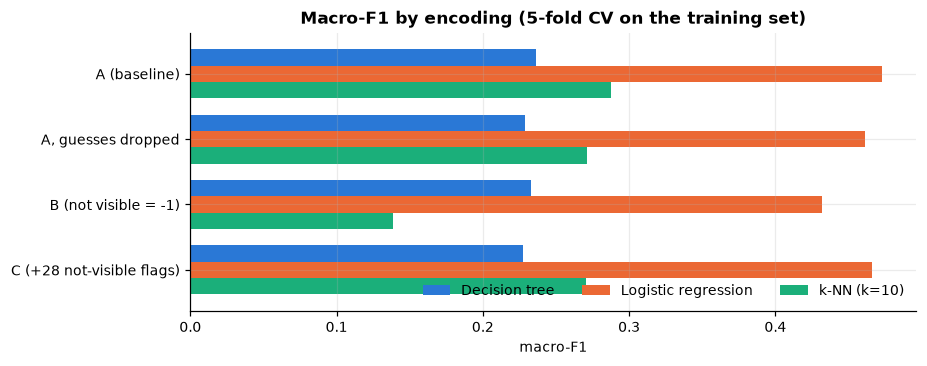

Fold-to-fold std of the scores: 0.004 to 0.014


In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
table.plot.barh(ax=ax, color=[BLUE, ORANGE, AQUA], width=0.75)
ax.invert_yaxis()
ax.set(title='Macro-F1 by encoding (5-fold CV on the training set)', xlabel='macro-F1', ylabel='')
ax.legend(loc='lower right', ncols=3)
plt.tight_layout()
save_figure(fig, 'certainty_experiment')
plt.show()

print('Fold-to-fold std of the scores:', results['std'].round(3).min(), 'to', results['std'].round(3).max())

## 3. Decision

Variant **A is the best option, or tied within noise, for every model** (decision tree 0.237, logistic regression
0.473, k-NN 0.283):

- **Dropping guessing positives** (the untested `dataPrep` switch) lowers every model by about 1 point (0.008 to 0.012).
- **Variant C** is within about 1 point of A, the same result the random forest found.
- **Variant B hurts badly for k-NN** (0.137, half of A) and costs logistic regression 4 points. Coding "not visible"
  as −1 puts hidden body parts far away from both "present" and "absent", so they dominate the distance calculation
  that k-NN relies on (Lecture 3).
- For the decision tree all options are within about 1 point, inside the fold-to-fold noise shown above.

**Decision:** keep **variant A** (raw 0/1) as the default input for all models, with `DROP_GUESSING_POSITIVES = False`.
This agrees with the decision tree and random forest notebooks, which found no measurable benefit from B or C.

**Why the alternatives do not help:** "guessing" answers are marked present about as often as "definitely" answers
(see `dataPrep.ipynb` §6), so they still carry real information; dropping or down-weighting them mostly removes correct
labels. And a hidden body part tells a model little about which species it is.